# Park et al. (2023): Mean-CUSUM smoothing and peak exploration

**Purpose:** Exercise the repository implementation of `mean_cusum_curves` and `smooth_cusum_curve` using reproducible synthetic positive-mean multichannel observations.

**Status:** exploratory implementation check, **not** numerical reproduction of the paper or a validated change detector. Park's reported smoothing span is 0.1; local-linear degree 1 and tricube weights are reconstruction choices. The span acts on candidate positions retained after `min_segment` exclusion, not the full time domain.

The returned raw and smoothed peak estimates are descriptive. Park's unimodality and peak-agreement decision rules have **not** been implemented here.

## 1. Import the current repository implementation

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "src" / "detection" / "stage1" / "park_mean_cusum.py").exists():
    raise FileNotFoundError("Run from the repository root or notebooks/ directory.")
sys.path.insert(0, str(ROOT))

from src.detection.stage1.park_mean_cusum import mean_cusum_curves, smooth_cusum_curve
print("Repository root:", ROOT)

Repository root: C:\Users\b01085983\Documents\GitHub\ewma_covariate_shift_demo


## 2. Deterministic synthetic data with a known mean-change position
All channel means remain positive, as required by the repository's normalisation. This is a synthetic breakpoint experiment, not EEG data.

In [2]:
rng = np.random.default_rng(202310)
n, p, true_break = 240, 4, 120
data = rng.normal(loc=np.array([4.0, 5.0, 6.0, 7.0]), scale=0.45, size=(n, p))
data[true_break:] += np.array([1.3, 0.8, 1.6, 0.6])
assert np.all(data.mean(axis=0) > 0)
result = mean_cusum_curves(data, min_segment=8)
print("Known synthetic change:", true_break)
print("Raw peaks:", result["b_max"], result["b_avg"], "gap:", result["agreement_gap"])
print("Smoothed peaks:", result["b_max_smoothed"], result["b_avg_smoothed"], "gap:", result["agreement_gap_smoothed"])
print("Configuration:", result["smoothing"])

Known synthetic change: 120
Raw peaks: 119 120 gap: 1
Smoothed peaks: 118 120 gap: 2
Configuration: {'span': 0.1, 'degree': 1, 'kernel': 'tricube', 'domain': 'retained_candidate_positions'}


## 3. Output schema, array shapes, and peak-index consistency

In [3]:
positions = np.asarray(result["positions"])
expected = len(positions)
for key in ("maximum", "average", "maximum_smoothed", "average_smoothed"):
    assert len(result[key]) == expected, (key, len(result[key]), expected)
assert np.asarray(result["by_channel"]).shape == (p, expected)
assert result["b_max"] == int(positions[np.argmax(result["maximum"])])
assert result["b_avg"] == int(positions[np.argmax(result["average"])])
assert result["b_max_smoothed"] == int(positions[np.argmax(result["maximum_smoothed"])])
assert result["b_avg_smoothed"] == int(positions[np.argmax(result["average_smoothed"])])
assert result["agreement_gap_smoothed"] == abs(result["b_max_smoothed"] - result["b_avg_smoothed"])
assert result["smoothing"]["domain"] == "retained_candidate_positions"
print("PASS: output shapes, smoothed peak fields, and metadata")

PASS: output shapes, smoothed peak fields, and metadata


## 4. Raw versus smoothed aggregated curves
The vertical reference is the known synthetic change; it is not an inferred alarm.

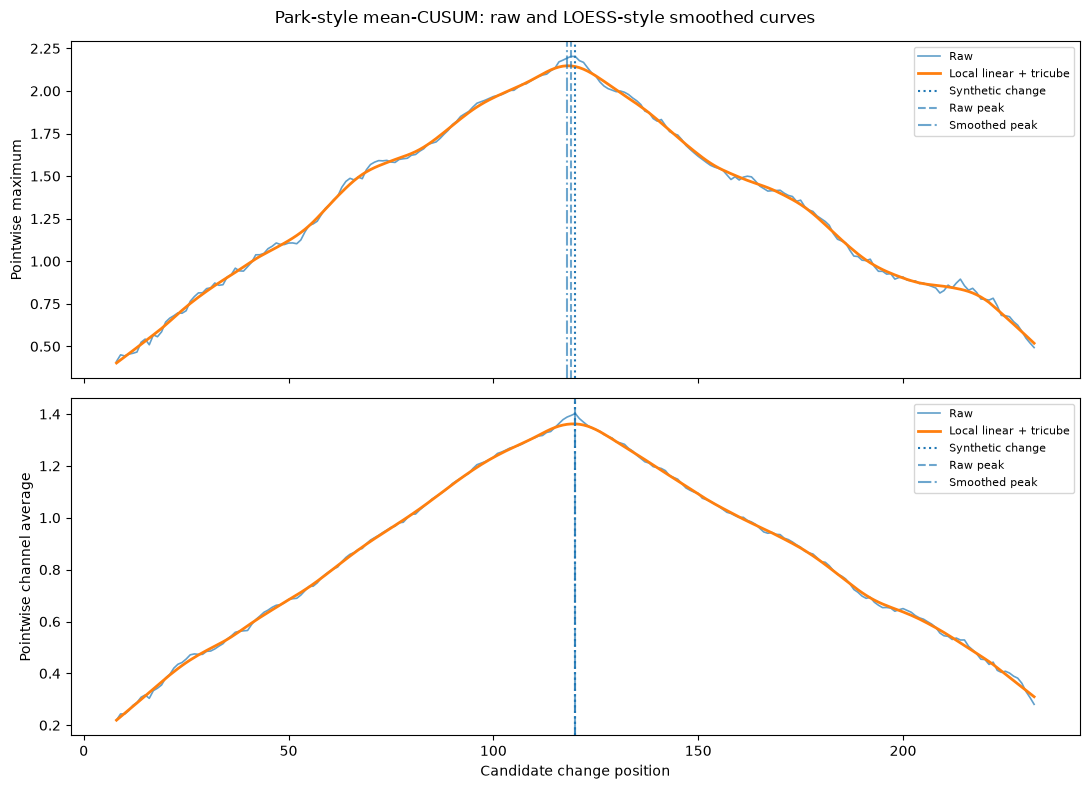

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
for ax, label, raw_key, smooth_key, b_raw, b_smooth in [
    (axes[0], "Pointwise maximum", "maximum", "maximum_smoothed", "b_max", "b_max_smoothed"),
    (axes[1], "Pointwise channel average", "average", "average_smoothed", "b_avg", "b_avg_smoothed"),
]:
    ax.plot(positions, result[raw_key], label="Raw", linewidth=1.2, alpha=0.7)
    ax.plot(positions, result[smooth_key], label="Local linear + tricube", linewidth=2)
    ax.axvline(true_break, linestyle=":", label="Synthetic change")
    ax.axvline(result[b_raw], linestyle="--", alpha=0.65, label="Raw peak")
    ax.axvline(result[b_smooth], linestyle="-.", alpha=0.65, label="Smoothed peak")
    ax.set_ylabel(label)
    ax.legend(loc="best", fontsize=8)
axes[-1].set_xlabel("Candidate change position")
fig.suptitle("Park-style mean-CUSUM: raw and LOESS-style smoothed curves")
fig.tight_layout()
plt.show()

## 5. Sensitivity: degree 1 versus degree 2
Both degree choices use the same span and kernel; degree 2 is a **sensitivity experiment**, not a claimed author configuration.

degree=1: b_max=118, b_avg=120, gap=2
degree=2: b_max=119, b_avg=119, gap=0


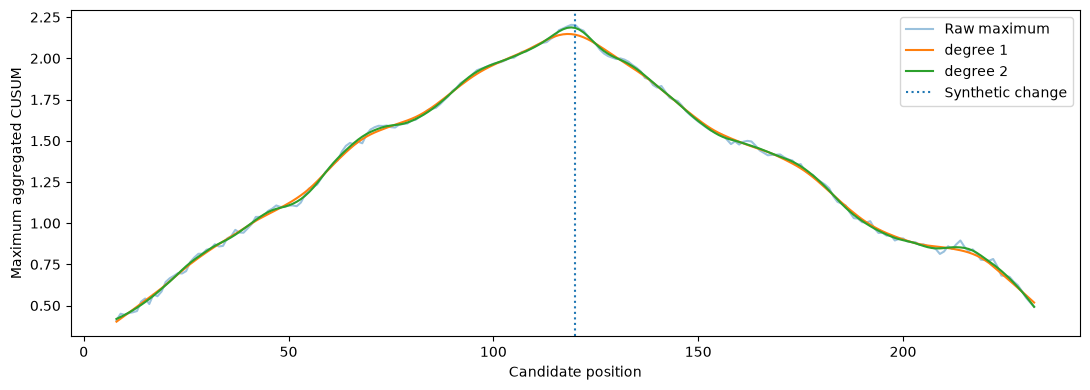

In [5]:
rows = []
for degree in (1, 2):
    m = smooth_cusum_curve(positions, result["maximum"], span=0.1, degree=degree)
    a = smooth_cusum_curve(positions, result["average"], span=0.1, degree=degree)
    rows.append((degree, int(positions[m.argmax()]), int(positions[a.argmax()])))
for degree, bmax, bavg in rows:
    print(f"degree={degree}: b_max={bmax}, b_avg={bavg}, gap={abs(bmax-bavg)}")
plt.figure(figsize=(11, 4))
plt.plot(positions, result["maximum"], alpha=0.45, label="Raw maximum")
for degree in (1, 2):
    plt.plot(positions, smooth_cusum_curve(positions, result["maximum"], span=0.1, degree=degree), label=f"degree {degree}")
plt.axvline(true_break, linestyle=":", label="Synthetic change")
plt.xlabel("Candidate position")
plt.ylabel("Maximum aggregated CUSUM")
plt.legend()
plt.tight_layout()
plt.show()

## 6. No-change example: peaks do not imply confirmed change
A CUSUM argmax always produces a location, even without a planted breakpoint. Do not interpret that location as detection confirmation.

In [6]:
rng_null = np.random.default_rng(202311)
stable = rng_null.normal(loc=np.array([4., 5., 6., 7.]), scale=0.45, size=(n, p))
null_result = mean_cusum_curves(stable, min_segment=8)
print("No planted change; descriptive smoothed peaks:",
      null_result["b_max_smoothed"], null_result["b_avg_smoothed"])
assert len(null_result["maximum_smoothed"]) == len(null_result["positions"])

No planted change; descriptive smoothed peaks: 207 206


## 7. Validation checks
Reject nonpositive channel means, nonfinite observations, incorrect input shape, and invalid smoother inputs.

In [7]:
def must_raise(fn, exception=ValueError):
    try:
        fn()
    except exception:
        return
    raise AssertionError(f"Expected {exception.__name__}")

must_raise(lambda: mean_cusum_curves(np.ones(40)))
must_raise(lambda: mean_cusum_curves(np.column_stack((np.ones(40), -np.ones(40)))))
bad = np.ones((40, 2))
bad[0, 0] = np.nan
must_raise(lambda: mean_cusum_curves(bad))
must_raise(lambda: smooth_cusum_curve([1, 1, 2], [1, 2, 3]))
must_raise(lambda: smooth_cusum_curve([1, 2, 3], [1, 2, 3], span=0))
must_raise(lambda: smooth_cusum_curve([1, 2, 3], [1, 2, 3], degree=3))
print("PASS: validation checks")

PASS: validation checks


## 8. Short-series edge case and current implementation limitation
The smallest allowed observation count can yield fewer than three retained candidates (e.g. n=17, min_segment=8). The CUSUM computation accepts these inputs, but the smoother requires at least three candidate positions. This notebook documents the mismatch; it deliberately does not silently change the production function.

In [8]:
short_data = np.full((17, 2), 3.0)
must_raise(lambda: mean_cusum_curves(short_data, min_segment=8))
print("KNOWN LIMITATION: n=17 and min_segment=8 passes the CUSUM segment guard but fails smoothing (only 2 candidates).")
print("Follow-up: validate candidate count early, or specify a deliberate short-series policy.")

KNOWN LIMITATION: n=17 and min_segment=8 passes the CUSUM segment guard but fails smoothing (only 2 candidates).
Follow-up: validate candidate count early, or specify a deliberate short-series policy.


## 9. Conclusions and next development step
- Compare raw and smoothed peak positions, never overwrite the original outputs.
- Span=0.1 applies to retained candidate indices and is not smoothing the full domain.
- Local polynomial degree and tricube weights are implementation choices.
- **Not implemented:** Park's unimodality check, peak-agreement threshold/criterion, and final detector decision.
- **Not established:** published numerical reproduction, false-positive rate, or detection power.

To extend this work, implement explicit unimodality and peak-agreement rules in the production detector, then test on multiple seeded scenarios. Keep synthetic demonstration outcomes separate from empirical benchmark claims.